# 01 — Explore the data

Open the HDF5 chunks in `data/` and list every variable that is available.

Each `chunk_XXXXX.h5` file holds **100 shots**. Every variable is stored with the shot as its first axis,
and most have a `<name>_stamp` companion with the acquisition timestamp (seconds since epoch).

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 80)

# Find the repo's data/ folder whether the kernel starts in the repo root or in notebooks/
DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
files = sorted(DATA_DIR.glob("chunk_*.h5"))
print(f"{len(files)} files in {DATA_DIR}")
print(f"Total size: {sum(f.stat().st_size for f in files) / 1e9:.2f} GB")

21 files in /Users/angilard/Desktop/Fast-Approximate/data
Total size: 3.45 GB


## File-level metadata

In [2]:
with h5py.File(files[0], "r") as f:
    for k, v in f.attrs.items():
        print(f"{k:15s} {v}")

chunk           chunk_00000
converted       2026-10-12T20:58:35.633651
n_shots         100
source_folder   /nfs/cs-ccr-nfsop/nfs6/vol29/Linux/data/clear/Python/experiment/hackatlon/measured_data/acquisition_2026-10-09_07-46-07
time_unit       pc_time and datetime stamps: seconds since epoch


## Variable inventory

Walk the whole file tree and list every dataset with its shape, dtype and the control-system device it comes from
(the mapping is stored as attributes on the `parameters` group).

In [3]:
def decode(x):
    return x.decode() if isinstance(x, bytes) else x


def inventory(path):
    rows = []
    with h5py.File(path, "r") as f:
        devices = dict(f["parameters"].attrs)

        def visit(name, obj):
            ragged = isinstance(obj, h5py.Group) and obj.attrs.get("ragged", False)
            parent = name.rsplit("/", 1)[0] if "/" in name else ""
            if not (isinstance(obj, h5py.Dataset) or ragged) or (parent and f[parent].attrs.get("ragged", False)):
                return
            top = name.split("/")[0]
            if ragged:  # variable-length per shot, stored as one dataset per shot
                lengths = {obj[k].shape for k in obj}
                rows.append({
                    "variable": name,
                    "group": top,
                    "shape": (len(obj), "ragged"),
                    "per_shot_shape": max(lengths),
                    "dtype": str(obj[next(iter(obj))].dtype),
                    "example (shot 0)": f"ragged, per-shot shapes {sorted(lengths)}",
                    "device": devices.get(top, ""),
                })
                return
            sample = obj[0] if obj.shape else obj[()]
            if obj.dtype.kind in "OS":
                example = decode(sample if np.ndim(sample) == 0 else sample.flat[0])
            elif np.ndim(sample) == 0:
                example = sample
            else:
                example = f"array{np.shape(sample)}"
            rows.append({
                "variable": name,
                "group": top if "/" in name else "",
                "shape": obj.shape,
                "per_shot_shape": obj.shape[1:],
                "dtype": str(obj.dtype) if obj.dtype.kind != "O" else "str",
                "example (shot 0)": example,
                "device": devices.get(top.removesuffix("_stamp"), ""),
            })

        f.visititems(visit)
    return pd.DataFrame(rows)


inv = inventory(files[0])
print(f"{len(inv)} datasets")
inv

123 datasets


,variable,group,shape,per_shot_shape,dtype,example (shot 0),device
0,BCM_GUN,,"(100,)",(),float64,5.504729,CA.BCMGUN/Acquisition#charge | SCT.USER.SETUP
1,BCM_GUN_stamp,,"(100,)",(),float64,1791524774.384164,CA.BCMGUN/Acquisition#charge | SCT.USER.SETUP
2,BTV0125/acqImageNumberDiffFromLast,BTV0125,"(100,)",(),int64,1,CA.BTV0125.DigiCam/LastImage |
3,BTV0125/acqImageTransmissionTime,BTV0125,"(100,)",(),int64,200360158,CA.BTV0125.DigiCam/LastImage |
4,BTV0125/acqImageTransmissionTime_units,BTV0125,"(100,)",(),str,ns,CA.BTV0125.DigiCam/LastImage |
5,BTV0125/cycleNameGlob,BTV0125,"(100,)",(),str,SCT.USER.SETUP,CA.BTV0125.DigiCam/LastImage |
6,BTV0125/cycleNbGlob,BTV0125,"(100,)",(),int64,1,CA.BTV0125.DigiCam/LastImage |
7,BTV0125/cycleStampGlob,BTV0125,"(100,)",(),int64,1791524774369000000,CA.BTV0125.DigiCam/LastImage |
8,BTV0125/frameNumber,BTV0125,"(100,)",(),int64,8810,CA.BTV0125.DigiCam/LastImage |
9,BTV0125/height,BTV0125,"(100,)",(),int64,1216,CA.BTV0125.DigiCam/LastImage |


### Device mapping (`parameters` attributes)

In [4]:
with h5py.File(files[0], "r") as f:
    devices = pd.Series(dict(f["parameters"].attrs), name="device / property | cycle")
devices.to_frame()

,device / property | cycle
BCM_GUN,CA.BCMGUN/Acquisition#charge | SCT.USER.SETUP
BTV0125,CA.BTV0125.DigiCam/LastImage |
DHG0130,CA.DHG0130/Acquisition#currentAverage | SCT.USER.SETUP
HUMID1,CK.CLIME-HUMID-01/Acquisition#data |
HUMID2,CK.CLIME-HUMID-02/Acquisition#data |
HUMID3,CK.CLIME-HUMID-03/Acquisition#data |
HUMID4,CK.CLIME-HUMID-04/Acquisition#data |
PGIA,CA.PGIA-SA/SamplesFromTrigger#samples | SCT.USER.SETUP
PGIP,CA.PGIP-SA/SamplesFromTrigger#samples | SCT.USER.SETUP
PGLA,CA.PGLA-SA/SamplesFromTrigger | SCT.USER.SETUP


### Variables grouped by kind

- **scalars** — one number per shot (charges, currents, temperatures, humidities, laser power, timestamps)
- **waveforms** — 1D trace per shot (pickups / scope)
- **images** — 2D camera frame per shot (BTV screen)

In [5]:
numeric = inv[inv["dtype"] != "str"]
kind = np.select(
    [numeric["per_shot_shape"].map(len) == 0, numeric["variable"].str.endswith("image2D")],
    ["scalar", "image"],
    default="waveform",
)
numeric = numeric.assign(kind=kind)
for k, df in numeric.groupby("kind"):
    print(f"\n=== {k} ({len(df)}) ===")
    print(df[["variable", "per_shot_shape", "dtype"]].to_string(index=False))


=== image (1) ===
       variable per_shot_shape dtype
BTV0125/image2D   (1216, 1936) int16

=== scalar (72) ===
                           variable per_shot_shape   dtype
                            BCM_GUN             () float64
                      BCM_GUN_stamp             () float64
 BTV0125/acqImageNumberDiffFromLast             ()   int64
   BTV0125/acqImageTransmissionTime             ()   int64
                BTV0125/cycleNbGlob             ()   int64
             BTV0125/cycleStampGlob             ()   int64
                BTV0125/frameNumber             ()   int64
                     BTV0125/height             ()   int64
             BTV0125/heightOriginal             ()   int64
                BTV0125/imageNumber             ()   int64
          BTV0125/imageTimeInterval             ()   int64
             BTV0125/imageTimeStamp             ()   int64
          BTV0125/imageTimeStampRaw             ()   int64
                     BTV0125/maxVal             ()   int64
 

## Check that all chunks have the same layout

Some variables are **ragged** in a few chunks: when a shot has a missing/empty array, the converter stores the
variable as a group of per-shot datasets (`shot_00100`, `shot_00101`, ...) flagged with `attrs["ragged"]`,
instead of one 2D array.

In [6]:
def variable_names(f):
    names = set()

    def visit(name, obj):
        if isinstance(obj, h5py.Group) and obj.attrs.get("ragged", False):
            names.add(name)
        elif isinstance(obj, h5py.Dataset) and not f[name.rsplit("/", 1)[0]].attrs.get("ragged", False):
            names.add(name)

    f.visititems(visit)
    return names


ref = set(inv["variable"])
layout = []
for path in files:
    with h5py.File(path, "r") as f:
        names = variable_names(f)
        ragged = {}
        for n in names:
            if isinstance(f[n], h5py.Group):
                empty = sum(f[n][k].size == 0 for k in f[n])
                ragged[n] = f"{empty} empty shots"
        layout.append({
            "file": path.name,
            "n_shots": f.attrs["n_shots"],
            "missing": sorted(ref - names),
            "extra": sorted(names - ref),
            "ragged": ragged,
        })
pd.DataFrame(layout)

,file,n_shots,missing,extra,ragged
0,chunk_00000.h5,100,[],[],"{'BTV0125/projDataSet1': '1 empty shots', 'BTV0125/imagePositionSet2': '1 em..."
1,chunk_00001.h5,100,[],[],"{'BTV0125/projDataSet1': '2 empty shots', 'BTV0125/imagePositionSet2': '2 em..."
2,chunk_00002.h5,100,[],[],"{'BTV0125/projDataSet1': '1 empty shots', 'BTV0125/imagePositionSet2': '1 em..."
3,chunk_00003.h5,100,[],[],{}
4,chunk_00004.h5,100,[],[],{}
5,chunk_00005.h5,100,[],[],"{'BTV0125/projDataSet1': '3 empty shots', 'BTV0125/imagePositionSet2': '3 em..."
6,chunk_00006.h5,100,[],[],"{'BTV0125/projDataSet1': '1 empty shots', 'BTV0125/imagePositionSet2': '1 em..."
7,chunk_00007.h5,100,[],[],"{'BTV0125/projDataSet1': '1 empty shots', 'BTV0125/imagePositionSet2': '1 em..."
8,chunk_00008.h5,100,[],[],{}
9,chunk_00009.h5,100,[],[],{}


## Load all scalar variables into one DataFrame

Scalars are small, so we can read them from every chunk at once (one row per shot).

In [7]:
scalar_vars = numeric.loc[numeric["kind"] == "scalar", "variable"].tolist()


def load_scalars(paths, variables):
    frames = []
    for path in paths:
        with h5py.File(path, "r") as f:
            df = pd.DataFrame({v: f[v][:] for v in variables})
            df["chunk"] = path.stem
            frames.append(df)
    return pd.concat(frames, ignore_index=True)


scalars = load_scalars(files, scalar_vars)
n_inf = np.isinf(scalars.select_dtypes("number")).sum()
print("inf values replaced by NaN:", n_inf[n_inf > 0].to_dict())
scalars = scalars.replace([np.inf, -np.inf], np.nan)
scalars["time"] = pd.to_datetime(scalars["pc_time"], unit="s")
print(scalars.shape, "| from", scalars["time"].min(), "to", scalars["time"].max())
scalars.head()

inf values replaced by NaN: {}
(2100, 74) | from 2026-10-09 05:46:14.798456907 to 2026-10-09 06:28:12.792737961


,BCM_GUN,BCM_GUN_stamp,BTV0125/acqImageNumberDiffFromLast,BTV0125/acqImageTransmissionTime,BTV0125/cycleNbGlob,BTV0125/cycleStampGlob,BTV0125/frameNumber,BTV0125/height,BTV0125/heightOriginal,BTV0125/imageNumber,...,laser_scope/nSamples,laser_scope/sampleInterval_ns,laser_scope/vertGain_VperLSB,laser_scope/vertOffset_V,laser_scope_stamp,pc_time,shot,trigger_stamp,chunk,time
0,5.504729,1.791525e+09,1,200360158,1,1791524774369000000,8810,1216,1216,8743,...,2002,0.025,0.000017,-0.164,1.791525e+09,1.791525e+09,0,1.791525e+09,chunk_00000,2026-10-09 05:46:14.798456907
1,5.504729,1.791525e+09,1,200360158,1,1791524774369000000,8810,1216,1216,8743,...,2002,0.025,0.000017,-0.164,1.791525e+09,1.791525e+09,1,1.791525e+09,chunk_00000,2026-10-09 05:46:15.258680105
2,5.354060,1.791525e+09,1,200389693,1,1791524775569000000,8811,1216,1216,8744,...,2002,0.025,0.000017,-0.164,1.791525e+09,1.791525e+09,2,1.791525e+09,chunk_00000,2026-10-09 05:46:15.992526054
3,5.264317,1.791525e+09,1,200397740,1,1791524776770000000,8812,1216,1216,8745,...,2002,0.025,0.000017,-0.164,1.791525e+09,1.791525e+09,3,1.791525e+09,chunk_00000,2026-10-09 05:46:17.223784924
4,5.137799,1.791525e+09,1,200432396,1,1791524777970000000,8813,1216,1216,8746,...,2002,0.025,0.000017,-0.164,1.791525e+09,1.791525e+09,4,1.791525e+09,chunk_00000,2026-10-09 05:46:18.451936960


In [8]:
# Summary statistics of the top-level scalar signals (skip the timestamp/bookkeeping columns)
main_scalars = [v for v in scalar_vars if "/" not in v and not v.endswith("_stamp") and v not in ("pc_time", "trigger_stamp", "shot")]
scalars[main_scalars].describe().T

,count,mean,std,min,25%,50%,75%,max
BCM_GUN,2100.0,5.601164,2.573954e-01,4.598656,5.436175,5.606112,5.772059,6.534118
DHG0130,2100.0,0.540438,1.352988e-03,0.535662,0.539480,0.540243,0.541389,0.544443
HUMID1,2100.0,48.781878,2.142932e-01,48.437500,48.608398,48.730469,48.974609,49.487305
HUMID2,2100.0,44.131964,1.692720e-01,43.823242,43.994141,44.091797,44.238281,44.653320
HUMID3,2100.0,45.087193,1.561039e-01,44.775391,44.970703,45.068359,45.190430,45.629883
HUMID4,2100.0,47.383196,1.056696e-01,47.167969,47.314453,47.363281,47.436523,47.753906
SNH_110,2100.0,220.003645,7.533383e-03,219.983994,220.000000,220.005005,220.009995,220.026001
SNI_120,2100.0,330.304134,1.624616e-01,329.477814,330.210266,330.271301,330.393372,330.668060
TEMP1,2100.0,19.716204,1.840548e-02,19.628906,19.702148,19.714355,19.726562,19.799805
TEMP2,2100.0,21.993960,3.794419e-02,21.875000,21.960449,21.997070,22.021484,22.155762


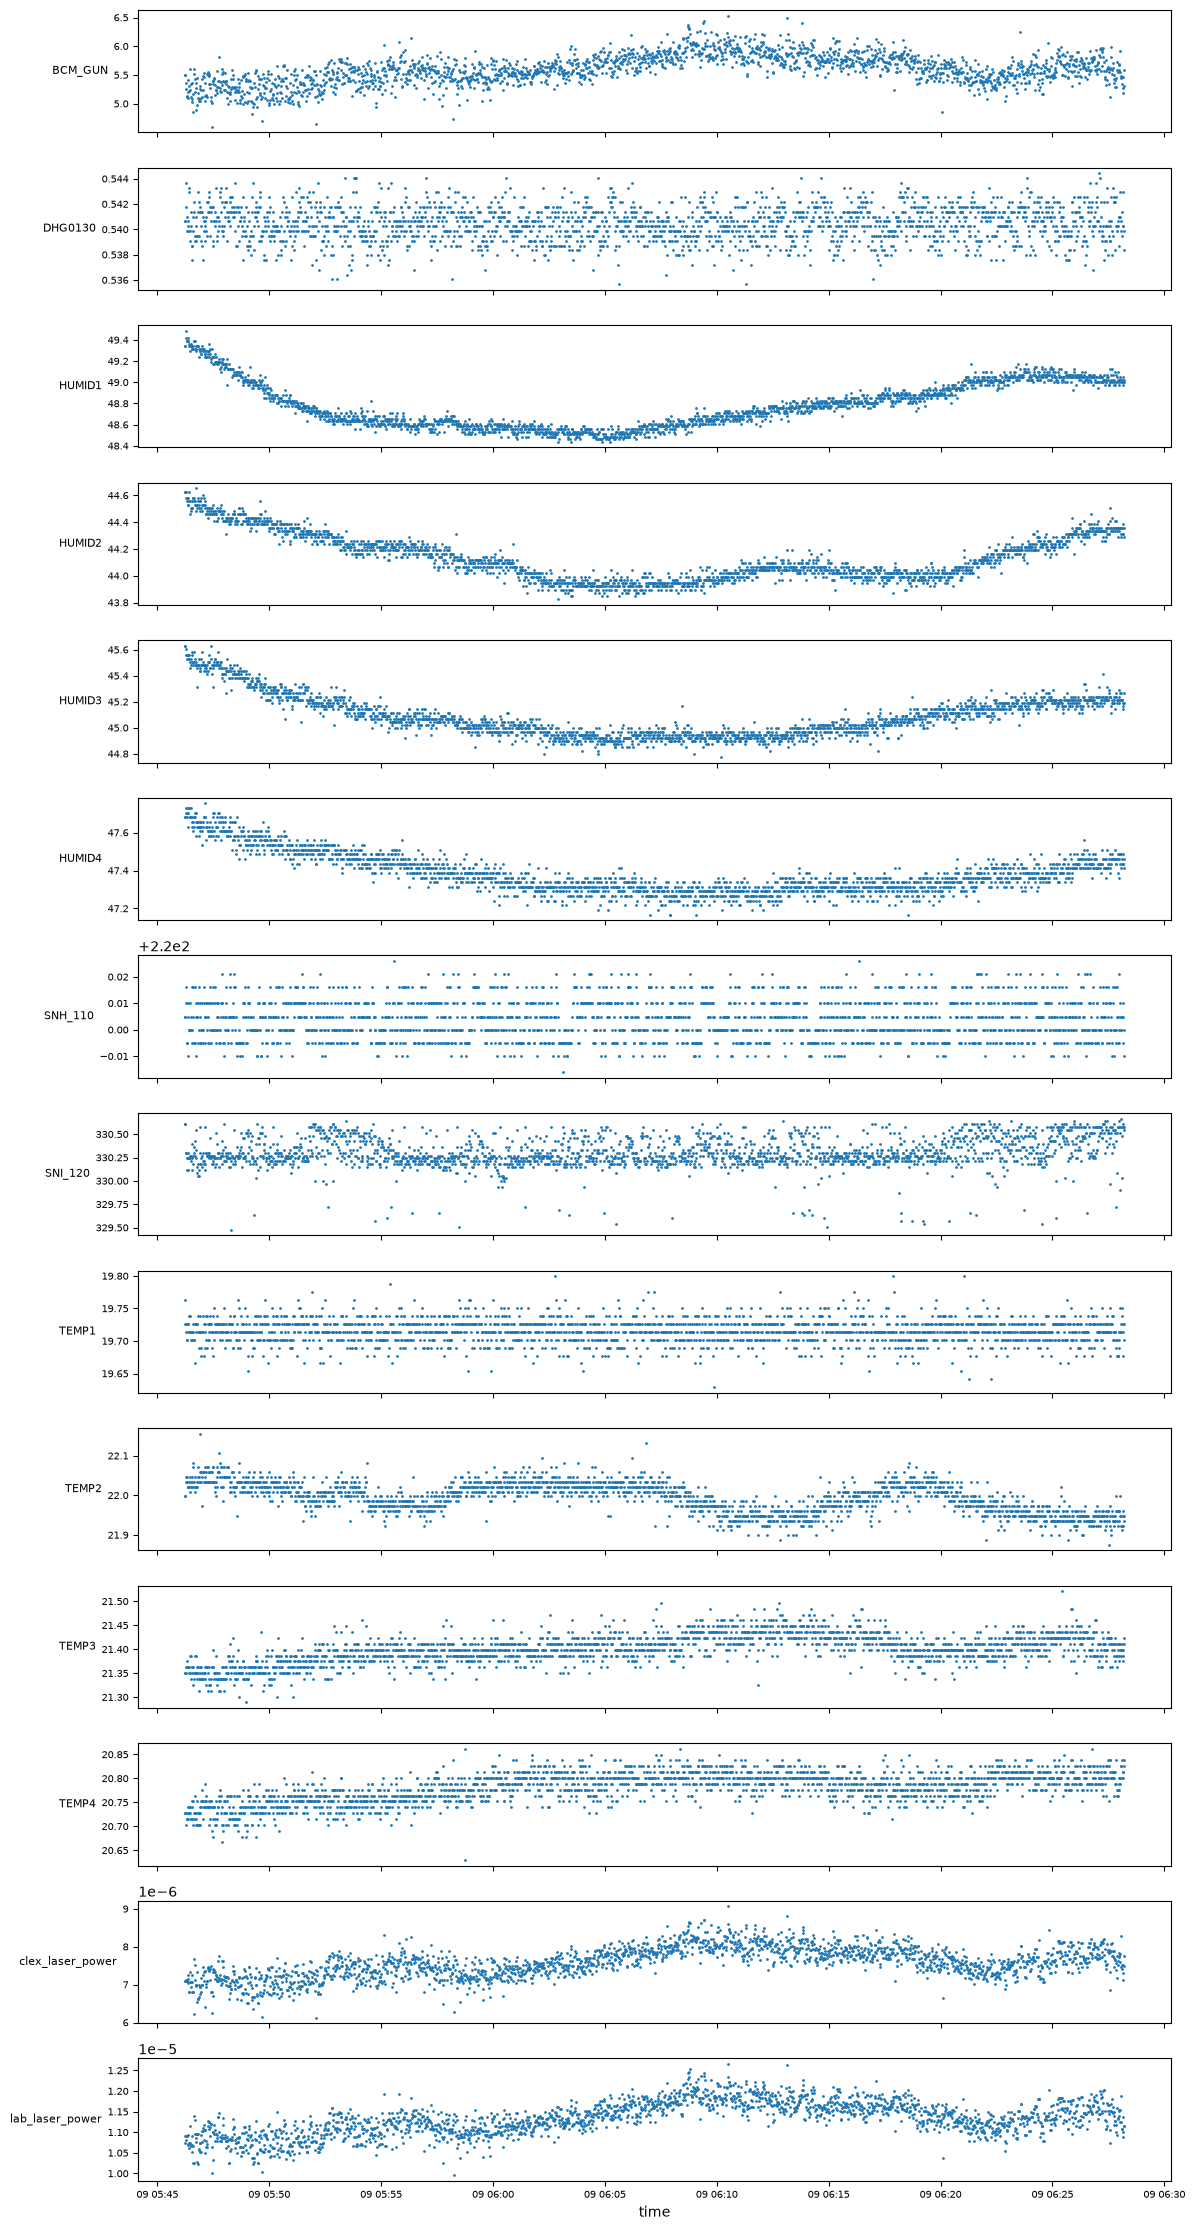

In [9]:
fig, axes = plt.subplots(len(main_scalars), 1, figsize=(12, 1.6 * len(main_scalars)), sharex=True)
for ax, v in zip(axes, main_scalars):
    ax.plot(scalars["time"], scalars[v], ".", ms=2)
    ax.set_ylabel(v, rotation=0, ha="right", va="center", fontsize=8)
    ax.tick_params(labelsize=7)
axes[-1].set_xlabel("time")
fig.tight_layout()

## Look at one shot: waveforms and camera image

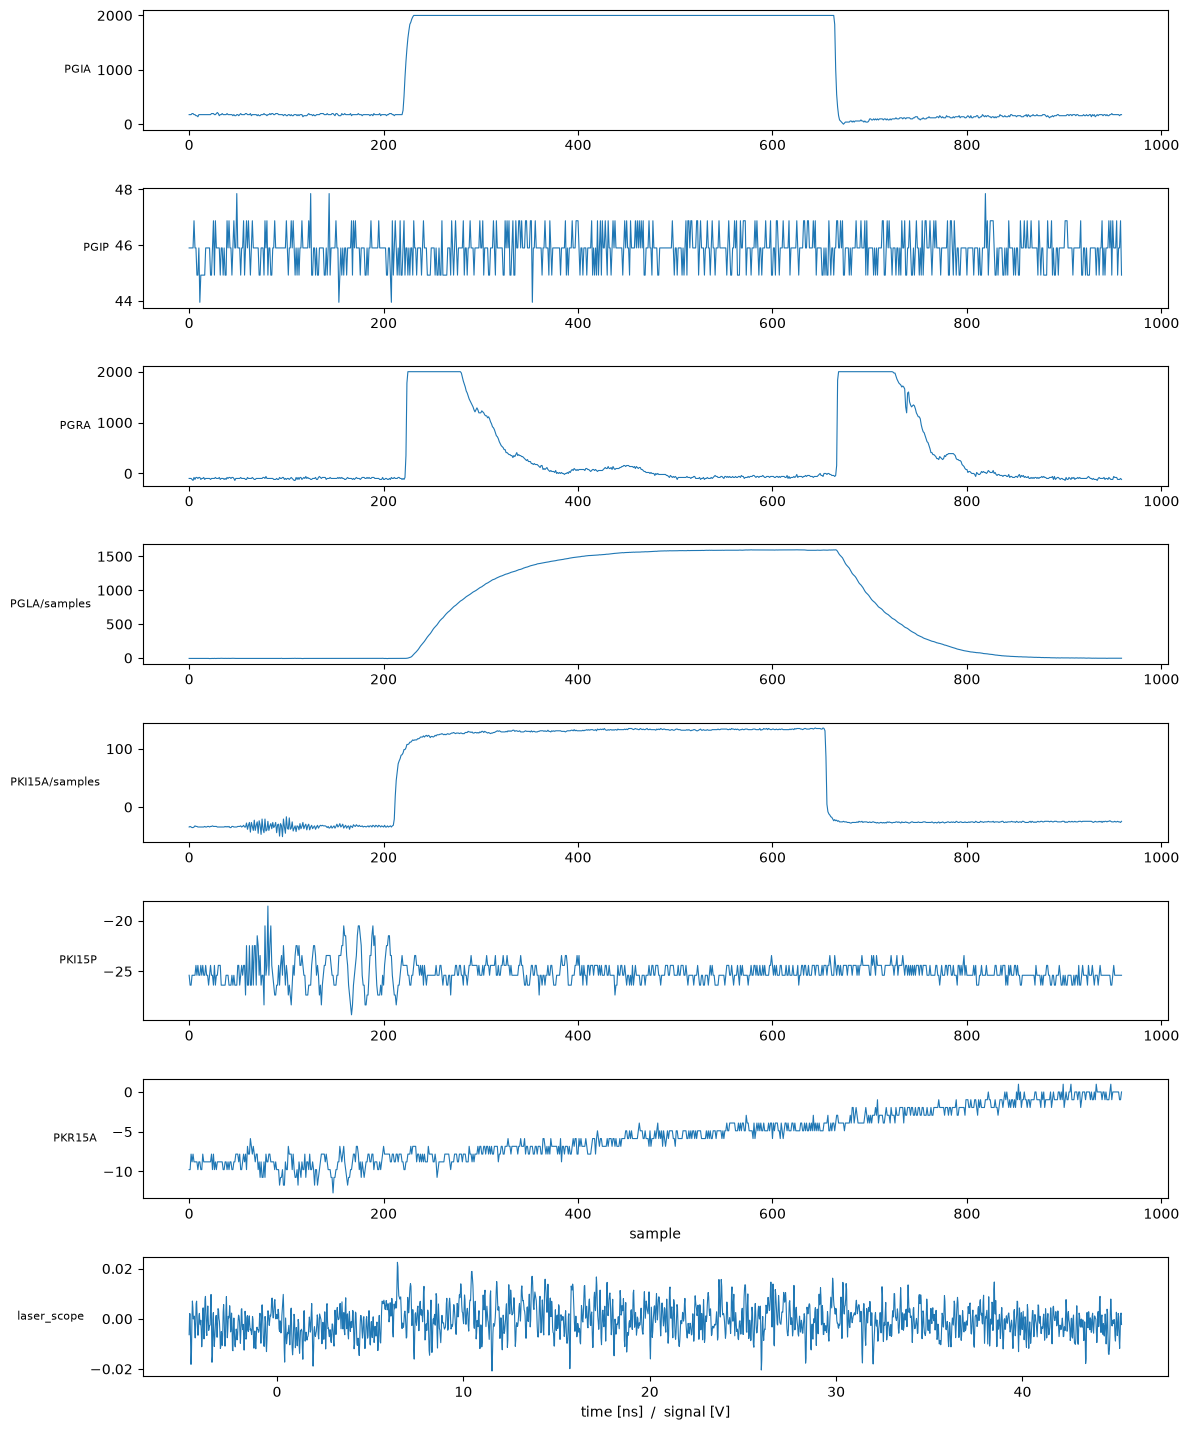

In [10]:
SHOT = 0
with h5py.File(files[0], "r") as f:
    waveforms = {
        "PGIA": f["PGIA"][SHOT, 0],
        "PGIP": f["PGIP"][SHOT, 0],
        "PGRA": f["PGRA"][SHOT, 0],
        "PGLA/samples": f["PGLA/samples"][SHOT, 0],
        "PKI15A/samples": f["PKI15A/samples"][SHOT, 0],
        "PKI15P": f["PKI15P"][SHOT, 0],
        "PKR15A": f["PKR15A"][SHOT, 0],
    }
    scope_t = f["laser_scope/times"][SHOT]
    scope_v = f["laser_scope/signal"][SHOT]
    scope_units = decode(f["laser_scope/times_unit"][SHOT]), decode(f["laser_scope/signal_unit"][SHOT])

fig, axes = plt.subplots(len(waveforms) + 1, 1, figsize=(12, 1.8 * (len(waveforms) + 1)))
for ax, (name, y) in zip(axes, waveforms.items()):
    ax.plot(y, lw=0.8)
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
axes[-2].set_xlabel("sample")
axes[-1].plot(scope_t, scope_v, lw=0.8)
axes[-1].set_ylabel("laser_scope", rotation=0, ha="right", va="center", fontsize=8)
axes[-1].set_xlabel(f"time [{scope_units[0]}]  /  signal [{scope_units[1]}]")
fig.tight_layout()

image (1216, 1936) int16 min/max: 0 4095


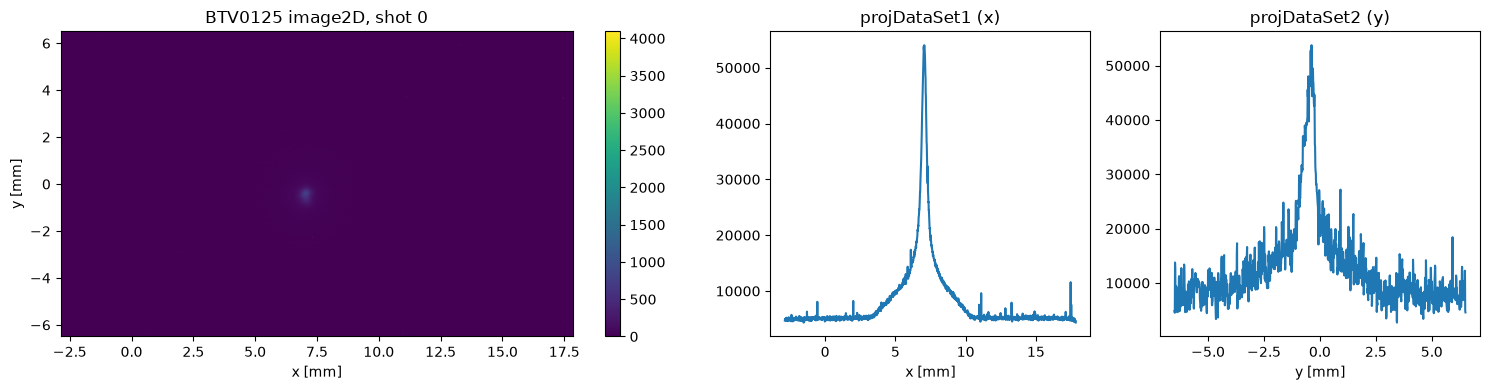

In [11]:
def one_shot(obj, i):
    """Shot i of a variable, whether stored as one array or as a ragged group of per-shot datasets."""
    return obj[i] if isinstance(obj, h5py.Dataset) else obj[sorted(obj)[i]][:]


with h5py.File(files[0], "r") as f:
    btv = f["BTV0125"]
    img = btv["image2D"][SHOT]
    x = one_shot(btv["imagePositionSet1"], SHOT)
    y = one_shot(btv["imagePositionSet2"], SHOT)
    unit = decode(btv["imagePositionSet1_unit"][SHOT])
    proj_x = one_shot(btv["projDataSet1"], SHOT)
    proj_y = one_shot(btv["projDataSet2"], SHOT)

print("image", img.shape, img.dtype, "min/max:", img.min(), img.max())
fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1, 1]})
im = axes[0].imshow(img, extent=[x[0], x[-1], y[-1], y[0]], aspect="auto", cmap="viridis")
axes[0].set(title=f"BTV0125 image2D, shot {SHOT}", xlabel=f"x [{unit}]", ylabel=f"y [{unit}]")
fig.colorbar(im, ax=axes[0])
axes[1].plot(x, proj_x); axes[1].set(title="projDataSet1 (x)", xlabel=f"x [{unit}]")
axes[2].plot(y, proj_y); axes[2].set(title="projDataSet2 (y)", xlabel=f"y [{unit}]")
fig.tight_layout()

## Helper: read any variable across all chunks

`load_variable("PGIA")` concatenates a variable over every file. Ragged variables are padded with NaN for the empty shots.
Careful with `BTV0125/image2D`: ~9.9 GB in memory for all 2100 shots.

In [12]:
def read_variable(f, name):
    obj = f[name]
    if isinstance(obj, h5py.Dataset):
        return obj[:]
    shots = [obj[k][:] for k in sorted(obj)]
    width = max(len(a) for a in shots)
    out = np.full((len(shots), width), np.nan)
    for i, a in enumerate(shots):
        out[i, : len(a)] = a
    return out


def load_variable(name, paths=files):
    arrays = []
    for path in paths:
        with h5py.File(path, "r") as f:
            arrays.append(read_variable(f, name))
    return np.concatenate(arrays)


pgia = load_variable("PGIA")
btv_x = load_variable("BTV0125/imagePositionSet1")
print("PGIA", pgia.shape)
print("BTV0125/imagePositionSet1", btv_x.shape, "| shots with no x-axis:", np.isnan(btv_x).all(axis=1).sum())

PGIA (2100, 1, 960)
BTV0125/imagePositionSet1 (2100, 1936) | shots with no x-axis: 15
